# Preprocessing Data / Feature Engineering:
## Loading Data

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import missingno as msno

In [2]:
df = pd.read_csv('financial_regression.csv')
df.head()

,date,sp500 open,sp500 high,sp500 low,sp500 close,sp500 volume,sp500 high-low,nasdaq open,nasdaq high,nasdaq low,...,palladium high,palladium low,palladium close,palladium volume,palladium high-low,gold open,gold high,gold low,gold close,gold volume
0,2010-01-14,114.49,115.14,114.42,114.93,115646960.0,0.72,46.26,46.520,46.22,...,45.02,43.86,44.84,364528.0,1.16,111.51,112.37,110.79,112.03,18305238.0
1,2010-01-15,114.73,114.84,113.20,113.64,212252769.0,1.64,46.46,46.550,45.65,...,45.76,44.40,45.76,442210.0,1.36,111.35,112.01,110.38,110.86,18000724.0
2,2010-01-18,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2010-01-19,113.62,115.13,113.59,115.06,138671890.0,1.54,45.96,46.640,45.95,...,47.08,45.70,46.94,629150.0,1.38,110.95,111.75,110.83,111.52,10467927.0
4,2010-01-20,114.28,114.45,112.98,113.89,216330645.0,1.47,46.27,46.604,45.43,...,47.31,45.17,47.05,643198.0,2.14,109.97,110.05,108.46,108.94,17534231.0


In [3]:
df.shape

(3904, 47)

In [4]:
df.info(verbose=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3904 entries, 0 to 3903
Data columns (total 47 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   date                3904 non-null   object 
 1   sp500 open          3719 non-null   float64
 2   sp500 high          3719 non-null   float64
 3   sp500 low           3719 non-null   float64
 4   sp500 close         3719 non-null   float64
 5   sp500 volume        3719 non-null   float64
 6   sp500 high-low      3719 non-null   float64
 7   nasdaq open         3719 non-null   float64
 8   nasdaq high         3719 non-null   float64
 9   nasdaq low          3719 non-null   float64
 10  nasdaq close        3719 non-null   float64
 11  nasdaq volume       3719 non-null   float64
 12  nasdaq high-low     3719 non-null   float64
 13  us_rates_%          176 non-null    float64
 14  CPI                 176 non-null    float64
 15  usd_chf             3694 non-null   float64
 16  eur_us

In [5]:
print(df.columns)

Index(['date', 'sp500 open', 'sp500 high', 'sp500 low', 'sp500 close',
       'sp500 volume', 'sp500 high-low', 'nasdaq open', 'nasdaq high',
       'nasdaq low', 'nasdaq close', 'nasdaq volume', 'nasdaq high-low',
       'us_rates_%', 'CPI', 'usd_chf', 'eur_usd', 'GDP', 'silver open',
       'silver high', 'silver low', 'silver close', 'silver volume',
       'silver high-low', 'oil open', 'oil high', 'oil low', 'oil close',
       'oil volume', 'oil high-low', 'platinum open', 'platinum high',
       'platinum low', 'platinum close', 'platinum volume',
       'platinum high-low', 'palladium open', 'palladium high',
       'palladium low', 'palladium close', 'palladium volume',
       'palladium high-low', 'gold open', 'gold high', 'gold low',
       'gold close', 'gold volume'],
      dtype='object')


In [6]:
print("Percentage of Missing Values (Before Feature Engineering) :")
(df.isnull().sum()/len(df))*100

Percentage of Missing Values (Before Feature Engineering) :


date                   0.000000
sp500 open             4.738730
sp500 high             4.738730
sp500 low              4.738730
sp500 close            4.738730
sp500 volume           4.738730
sp500 high-low         4.738730
nasdaq open            4.738730
nasdaq high            4.738730
nasdaq low             4.738730
nasdaq close           4.738730
nasdaq volume          4.738730
nasdaq high-low        4.738730
us_rates_%            95.491803
CPI                   95.491803
usd_chf                5.379098
eur_usd                5.379098
GDP                   98.539959
silver open            4.738730
silver high            4.738730
silver low             4.738730
silver close           4.738730
silver volume          4.738730
silver high-low        4.738730
oil open               4.738730
oil high               4.738730
oil low                4.738730
oil close              4.738730
oil volume             4.738730
oil high-low           4.738730
platinum open          4.738730
platinum

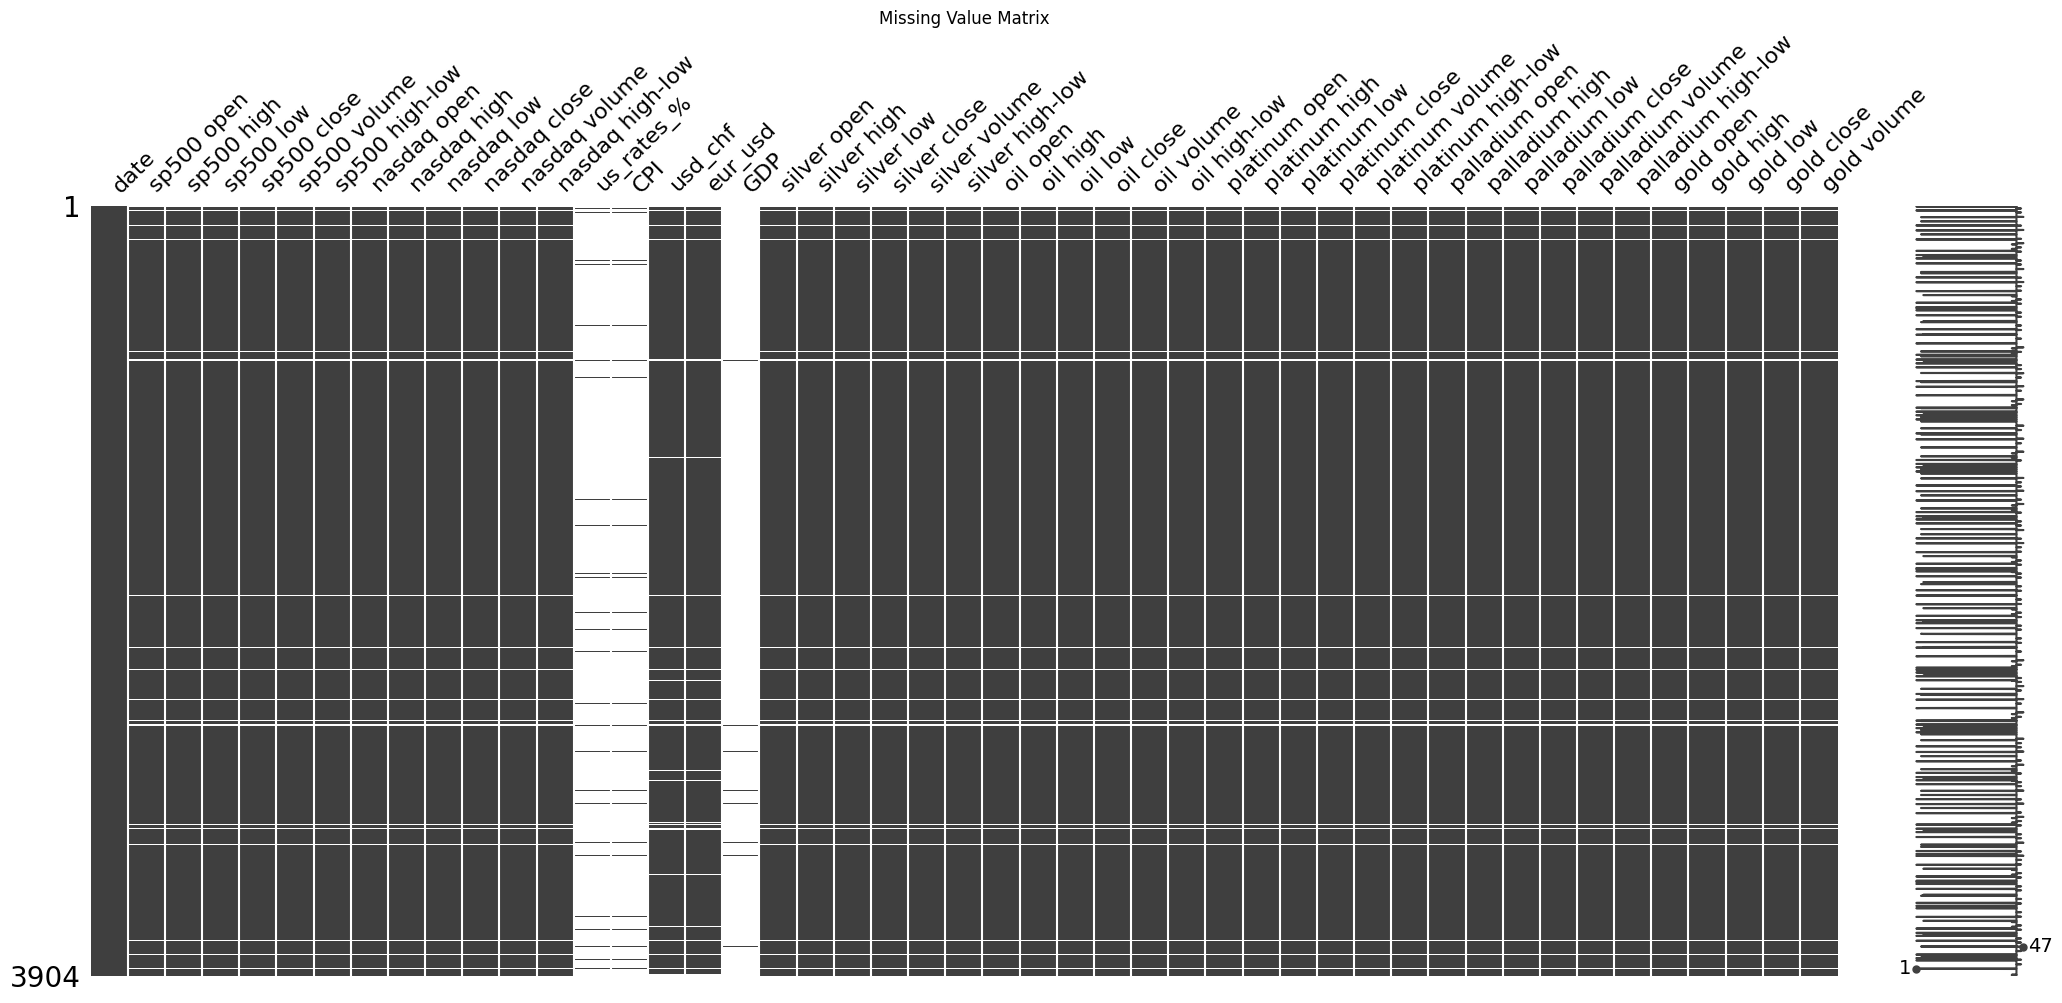

In [7]:
msno.matrix(df)
plt.title("Missing Value Matrix")
plt.show()

In [8]:
# We must standardize the dates in our data in order for our model to understand that markets close on Friday and re-open on Monday.

# Convert to datetime
df["date"] = pd.to_datetime(df["date"])

# Extract calendar components
df["DayOfWeek"] = df["date"].dt.dayofweek  # 0 = Monday, 4 = Friday
df["Month"] = df["date"].dt.month
df["Quarter"] = df["date"].dt.quarter
df["DayOfYear"] = df["date"].dt.dayofyear
df["IsMonthEnd"] = df["date"].dt.is_month_end.astype(int)

In [9]:
# Make sure the data are in chronological order BEFORE using shift()
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)

# Predict the next available trading day's gold closing price.
df["Target_Next_Close"] = df["gold close"].shift(-1)

# Lagged features use information available before today.
df["Close_Lag1"] = df["gold close"].shift(1)
df["Open_Lag1"] = df["gold open"].shift(1)

# Today's open-to-close return. This is valid if prediction is made after today's close.
df["Daily_Return"] = (df["gold close"] - df["gold open"]) / df["gold open"]

df[["gold open","gold close","Target_Next_Close","Close_Lag1","Open_Lag1","Daily_Return"]]


,gold open,gold close,Target_Next_Close,Close_Lag1,Open_Lag1,Daily_Return
0,111.51,112.03,110.86,NaN,NaN,0.004663
1,111.35,110.86,NaN,112.03,111.51,-0.004401
2,NaN,NaN,111.52,110.86,111.35,NaN
3,110.95,111.52,108.94,NaN,NaN,0.005137
4,109.97,108.94,107.37,111.52,110.95,-0.009366
...,...,...,...,...,...,...
3899,247.75,248.63,251.27,247.15,247.62,0.003552
3900,250.00,251.27,251.22,248.63,247.75,0.005080
3901,252.74,251.22,253.93,251.27,250.00,-0.006014
3902,253.06,253.93,250.87,251.22,252.74,0.003438


In [10]:
df.shape

(3904, 56)

In [11]:
print("Percentage of Missing Values (After Feature Engineering) :")
(df.isnull().sum()/len(df))*100

Percentage of Missing Values (After Feature Engineering) :


date                   0.000000
sp500 open             4.738730
sp500 high             4.738730
sp500 low              4.738730
sp500 close            4.738730
sp500 volume           4.738730
sp500 high-low         4.738730
nasdaq open            4.738730
nasdaq high            4.738730
nasdaq low             4.738730
nasdaq close           4.738730
nasdaq volume          4.738730
nasdaq high-low        4.738730
us_rates_%            95.491803
CPI                   95.491803
usd_chf                5.379098
eur_usd                5.379098
GDP                   98.539959
silver open            4.738730
silver high            4.738730
silver low             4.738730
silver close           4.738730
silver volume          4.738730
silver high-low        4.738730
oil open               4.738730
oil high               4.738730
oil low                4.738730
oil close              4.738730
oil volume             4.738730
oil high-low           4.738730
platinum open          4.738730
platinum

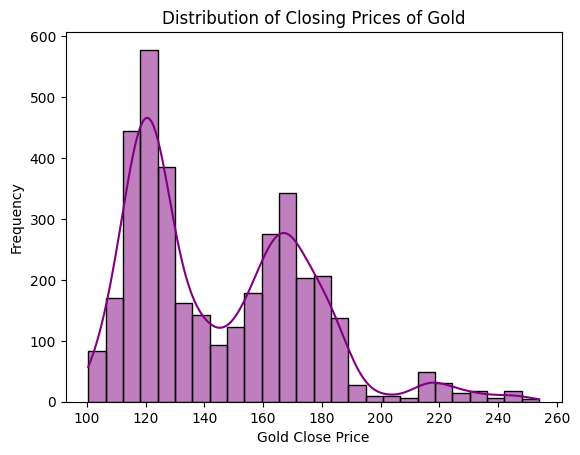

In [12]:
sns.histplot(df["Target_Next_Close"],color = 'purple',kde = True)
plt.title("Distribution of Closing Prices of Gold")
plt.xlabel("Gold Close Price")
plt.ylabel("Frequency")
plt.show()

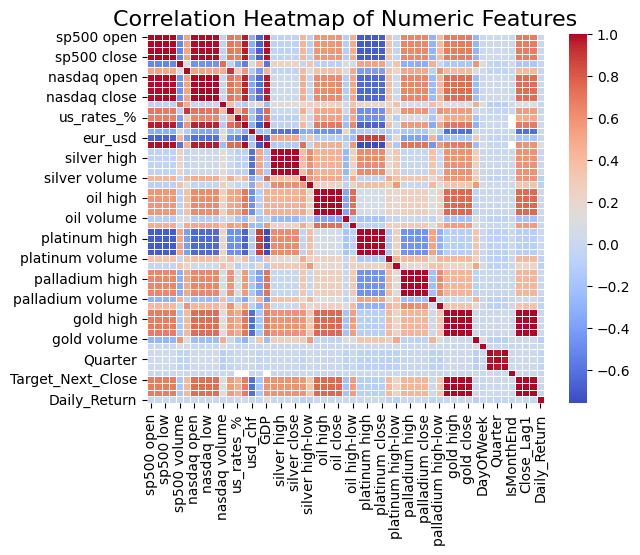

In [13]:
df_numeric = df.select_dtypes(include=[np.number])

sns.heatmap(df_numeric.corr(), cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap of Numeric Features', fontsize=16)
plt.show()

## Modeling part


In [14]:
# Target and lagged features were created above, after chronological sorting.
# This cell intentionally does not recreate them.


In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")

# sklearn
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# XGBoost
from xgboost import XGBRegressor

# SARIMAX
from statsmodels.tsa.statespace.sarimax import SARIMAX

# LSTM
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

print("Libraries loaded successfully.")

ModuleNotFoundError: No module named 'statsmodels'

In [ ]:
# Prepare the modeling data
# Chronological order was enforced before target creation above.
df = df.sort_values("date").reset_index(drop=True)

# Remove rows where the next trading day's target is unavailable.
model_df = df.dropna(subset=["Target_Next_Close"]).copy()

print("Modeling dataset shape:", model_df.shape)


Modeling dataset shape: (3718, 56)


In [ ]:
# SELECT THE PREDICTORS
features = [
    "sp500 open",
    "sp500 high",
    "sp500 low",
    "sp500 close",
    "sp500 volume",
    "sp500 high-low",

    "nasdaq open",
    "nasdaq high",
    "nasdaq low",
    "nasdaq close",
    "nasdaq volume",
    "nasdaq high-low",

    "silver open",
    "silver high",
    "silver low",
    "silver close",
    "silver volume",
    "silver high-low",

    "oil open",
    "oil high",
    "oil low",
    "oil close",
    "oil volume",
    "oil high-low",

    "platinum open",
    "platinum high",
    "platinum low",
    "platinum close",
    "platinum volume",
    "platinum high-low",

    "palladium open",
    "palladium high",
    "palladium low",
    "palladium close",
    "palladium volume",
    "palladium high-low",

    "gold open",
    "gold high",
    "gold low",
    "gold close",
    "gold volume",

    "DayOfWeek",
    "Month",
    "Quarter",
    "DayOfYear",
    "IsMonthEnd",
    "Daily_Return"
]

X = model_df[features]
y = model_df["Target_Next_Close"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (3718, 47)
y shape: (3718,)


In [ ]:
# TRAIN/SPLIT THE DATA
split_index = int(len(model_df) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

print("\nTraining period:")
print(model_df["date"].iloc[:split_index].min())
print("to")
print(model_df["date"].iloc[:split_index].max())

print("\nTesting period:")
print(model_df["date"].iloc[split_index:].min())
print("to")
print(model_df["date"].iloc[-1])

Training observations: 2974
Testing observations: 744

Training period:
2010-01-14 00:00:00
to
2021-11-04 00:00:00

Testing period:
2021-11-05 00:00:00
to
2024-10-22 00:00:00


In [ ]:
# NAIVE PERSISTENCE BASELINE
# Predict that the next trading day's close will equal today's close.
# This is an important baseline for financial price forecasting.
naive_pred = X_test["gold close"].values

naive_mae = mean_absolute_error(y_test, naive_pred)
naive_rmse = np.sqrt(mean_squared_error(y_test, naive_pred))
naive_r2 = r2_score(y_test, naive_pred)

naive_baseline = pd.DataFrame({
    "Model": ["Naive Persistence"],
    "MAE": [naive_mae],
    "RMSE": [naive_rmse],
    "R²": [naive_r2]
})

naive_baseline.round(4)


In [ ]:
# Handle Missing Values Inside the Pipeline
preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [ ]:
# Build the Linear Regression Model
linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,steps,"[('imputer', ...), ('scaler', ...)]"
,transform_input,None
,memory,None
,verbose,False
,missing_values,nan
,strategy,'median'
,fill_value,None


In [ ]:
# MAKE PREDICTION
y_train_pred = linear_model.predict(X_train)
y_test_pred = linear_model.predict(X_test)

In [ ]:
# EVALUATE THE MODEL
# USING: MAE, RMSE, R²
train_mae = mean_absolute_error(y_train, y_train_pred)
train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
train_r2 = r2_score(y_train, y_train_pred)

test_mae = mean_absolute_error(y_test, y_test_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
test_r2 = r2_score(y_test, y_test_pred)

results = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R²"],
    "Training": [train_mae, train_rmse, train_r2],
    "Testing": [test_mae, test_rmse, test_r2]
})

results

,Metric,Training,Testing
0,MAE,1.817994,3.660744
1,RMSE,4.959635,11.410681
2,R²,0.948042,0.742097


In [ ]:
# COMPARE ACTUAL VS PREDICTED
comparison = pd.DataFrame({
    "Date": model_df["date"].iloc[split_index:],
    "Actual": y_test.values,
    "Predicted": y_test_pred
})

comparison.head(10)

,Date,Actual,Predicted
3121,2021-11-05,170.45,170.036445
3122,2021-11-08,171.29,170.217140
3123,2021-11-09,173.15,171.280209
3124,2021-11-10,174.12,173.440307
3125,2021-11-11,174.45,174.186773
3126,2021-11-12,174.18,173.872327
3127,2021-11-15,172.92,173.864373
3128,2021-11-16,174.50,172.327299
3129,2021-11-17,173.94,174.944576
3130,2021-11-18,172.61,173.648257


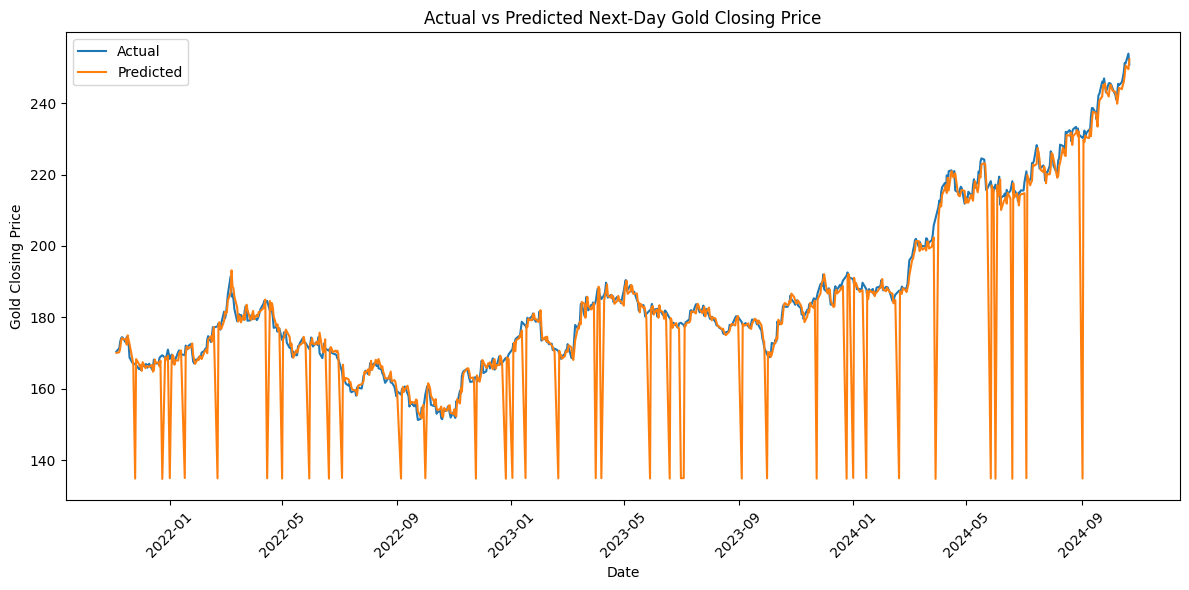

In [ ]:
# PLOT ACTUAL VS PREDICTED
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    comparison["Date"],
    comparison["Actual"],
    label="Actual"
)

plt.plot(
    comparison["Date"],
    comparison["Predicted"],
    label="Predicted"
)

plt.title("Actual vs Predicted Next-Day Gold Closing Price")
plt.xlabel("Date")
plt.ylabel("Gold Closing Price")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

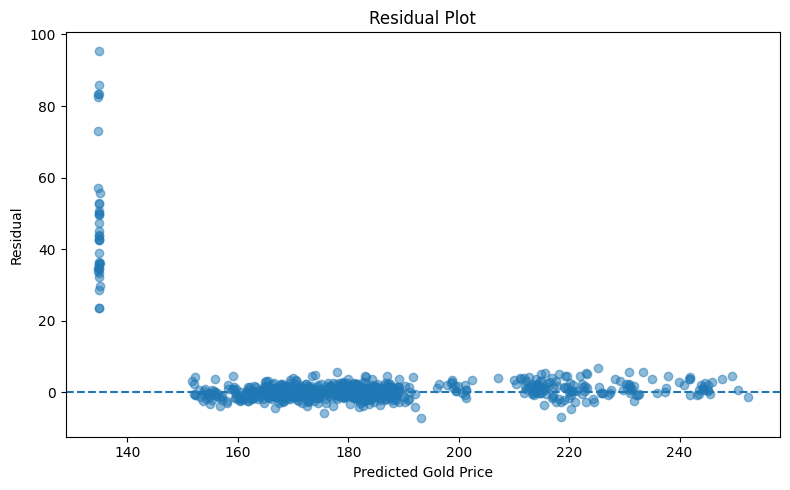

In [ ]:
# RESIDUAL ANALYSIS  
residuals = y_test - y_test_pred

plt.figure(figsize=(8, 5))

plt.scatter(y_test_pred, residuals, alpha=0.5)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.title("Residual Plot")
plt.xlabel("Predicted Gold Price")
plt.ylabel("Residual")
plt.tight_layout()
plt.show()

In [ ]:
# RIDGE REGRESSION
ridge_model = Pipeline([
    ("preprocessor", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])),
    ("model", Ridge(alpha=1.0))
])

ridge_model.fit(X_train, y_train)

ridge_pred = ridge_model.predict(X_test)

ridge_mae = mean_absolute_error(y_test, ridge_pred)
ridge_rmse = np.sqrt(mean_squared_error(y_test, ridge_pred))
ridge_r2 = r2_score(y_test, ridge_pred)

print("Ridge Regression")
print("----------------")
print("MAE :", ridge_mae)
print("RMSE:", ridge_rmse)
print("R²  :", ridge_r2)

Ridge Regression
----------------
MAE : 7.003322627677995
RMSE: 13.51520215230029
R²  : 0.6381915187315399


In [ ]:
# COMPARISON
model_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge Regression"
    ],
    "MAE": [
        test_mae,
        ridge_mae
    ],
    "RMSE": [
        test_rmse,
        ridge_rmse
    ],
    "R²": [
        test_r2,
        ridge_r2
    ]
})

model_comparison

,Model,MAE,RMSE,R²
0,Linear Regression,3.660744,11.410681,0.742097
1,Ridge Regression,7.003323,13.515202,0.638192


In [ ]:
# XGBOOST - SAME 80/20 HOLDOUT

xgb_model = XGBRegressor(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)
xgb_pred = xgb_model.predict(X_test)

xgb_mae = mean_absolute_error(y_test, xgb_pred)
xgb_rmse = np.sqrt(mean_squared_error(y_test, xgb_pred))
xgb_r2 = r2_score(y_test, xgb_pred)

xgb_average = pd.DataFrame({
    "Model": ["XGBoost"],
    "MAE": [xgb_mae],
    "RMSE": [xgb_rmse],
    "R²": [xgb_r2]
})

xgb_average.round(4)


,train_start,train_end,test_year
0,2008,2011,2012
1,2009,2012,2013
2,2010,2013,2014
3,2011,2014,2015
4,2012,2015,2016
5,2013,2016,2017
6,2014,2017,2018
7,2015,2018,2019
8,2016,2019,2020
9,2017,2020,2021


In [ ]:
# XGBoost is evaluated on the same chronological 20% test period as the other models.


,Test Year,Model,MAE,RMSE,R²
0,2012,XGBoost,4.2146,6.8314,-0.2569
1,2013,XGBoost,3.7953,7.4595,0.7282
2,2014,XGBoost,3.3451,6.7688,-0.8576
3,2015,XGBoost,5.8397,9.2555,-1.7440
4,2016,XGBoost,2.9851,4.8857,0.4929
5,2017,XGBoost,2.2227,3.6664,-0.3746
6,2018,XGBoost,1.2528,2.2766,0.8100
7,2019,XGBoost,6.6322,9.2142,-0.1466
8,2020,XGBoost,25.6586,28.3441,-3.6962
9,2021,XGBoost,3.2599,6.7078,-1.1187


,Model,MAE,RMSE,R²
0,XGBoost,5.4018,8.072,-0.4617


In [ ]:
# SARIMAX VARIABLES

sarimax_features = [
    "gold close",
    "silver close",
    "oil close",
    "sp500 close",
    "nasdaq close",
    "usd_chf"
]

sarimax_features

['gold close',
 'silver close',
 'oil close',
 'sp500 close',
 'nasdaq close',
 'usd_chf']

In [ ]:
# SARIMAX - SAME 80/20 HOLDOUT
# We model the next-day target using the current-day exogenous market variables.
# Missing exogenous values are imputed using training-set medians only.

sarimax_features = [
    "gold close",
    "silver close",
    "oil close",
    "sp500 close",
    "nasdaq close",
    "usd_chf"
]

X_sar_train = X_train[sarimax_features].copy()
X_sar_test = X_test[sarimax_features].copy()

train_medians = X_sar_train.median()
X_sar_train = X_sar_train.fillna(train_medians)
X_sar_test = X_sar_test.fillna(train_medians)

sarimax_model = SARIMAX(
    y_train,
    exog=X_sar_train,
    order=(1, 1, 1),
    seasonal_order=(0, 0, 0, 0),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarimax_fit = sarimax_model.fit(disp=False)
sarimax_pred = sarimax_fit.forecast(steps=len(X_sar_test), exog=X_sar_test)

sarimax_mae = mean_absolute_error(y_test, sarimax_pred)
sarimax_rmse = np.sqrt(mean_squared_error(y_test, sarimax_pred))
sarimax_r2 = r2_score(y_test, sarimax_pred)

sarimax_average = pd.DataFrame({
    "Model": ["SARIMAX"],
    "MAE": [sarimax_mae],
    "RMSE": [sarimax_rmse],
    "R²": [sarimax_r2]
})

sarimax_average.round(4)


2012: MAE=9.7473, RMSE=11.4603, R²=-2.5374
2013: MAE=27.0763, RMSE=30.6879, R²=-3.6000
2014: MAE=6.6918, RMSE=7.8345, R²=-1.4885
2015: MAE=4.9997, RMSE=6.3581, R²=-0.2949
2016: MAE=18.1642, RMSE=19.4965, R²=-7.0754
2017: MAE=10.7293, RMSE=11.2161, R²=-11.8643
2018: MAE=5.3195, RMSE=6.4350, R²=-0.5178
2019: MAE=10.6760, RMSE=13.7638, R²=-1.5584
2020: MAE=23.3867, RMSE=26.7662, R²=-3.1878
2021: MAE=9.8772, RMSE=10.7896, R²=-4.4817
2022: MAE=7.7099, RMSE=9.4499, R²=-0.1619
2023: MAE=10.0929, RMSE=11.3488, R²=-3.2854


,Test Year,Model,MAE,RMSE,R²
0,2012,SARIMAX,9.7473,11.4603,-2.5374
1,2013,SARIMAX,27.0763,30.6879,-3.6000
2,2014,SARIMAX,6.6918,7.8345,-1.4885
3,2015,SARIMAX,4.9997,6.3581,-0.2949
4,2016,SARIMAX,18.1642,19.4965,-7.0754
5,2017,SARIMAX,10.7293,11.2161,-11.8643
6,2018,SARIMAX,5.3195,6.4350,-0.5178
7,2019,SARIMAX,10.6760,13.7638,-1.5584
8,2020,SARIMAX,23.3867,26.7662,-3.1878
9,2021,SARIMAX,9.8772,10.7896,-4.4817


In [ ]:
# SARIMAX is now evaluated on the same chronological holdout as the other models.


,Model,MAE,RMSE,R²
0,SARIMAX,12.0392,13.8006,-3.3378


In [ ]:
# LSTM SETTINGS

lstm_features = [
    "gold close",
    "silver close",
    "oil close",
    "sp500 close",
    "nasdaq close",
    "usd_chf"
]

sequence_length = 20

print("LSTM features:")
print(lstm_features)

print("\nSequence length:", sequence_length)

LSTM features:
['gold close', 'silver close', 'oil close', 'sp500 close', 'nasdaq close', 'usd_chf']

Sequence length: 20


In [ ]:
# LSTM FUNCTION - CORRECTLY ALIGNED SEQUENCES

def run_lstm_holdout(train, test):
    X_train = train[lstm_features].copy()
    y_train = train["Target_Next_Close"].copy()
    X_test = test[lstm_features].copy()
    y_test = test["Target_Next_Close"].copy()

    # Fit preprocessing ONLY on training data.
    imputer = SimpleImputer(strategy="median")
    X_train = imputer.fit_transform(X_train)
    X_test = imputer.transform(X_test)

    scaler_X = MinMaxScaler()
    X_train = scaler_X.fit_transform(X_train)
    X_test = scaler_X.transform(X_test)

    scaler_y = MinMaxScaler()
    y_train_scaled = scaler_y.fit_transform(y_train.values.reshape(-1, 1))

    # For target y[i] = next trading day's close, the sequence includes X[i].
    X_sequences = []
    y_sequences = []
    for i in range(sequence_length - 1, len(X_train)):
        X_sequences.append(X_train[i-sequence_length+1:i+1])
        y_sequences.append(y_train_scaled[i])

    X_sequences = np.array(X_sequences)
    y_sequences = np.array(y_sequences)

    # Reserve the final 10% of the training period as chronological validation data.
    val_size = max(1, int(len(X_sequences) * 0.10))
    X_fit, X_val = X_sequences[:-val_size], X_sequences[-val_size:]
    y_fit, y_val = y_sequences[:-val_size], y_sequences[-val_size:]

    lstm_model = Sequential([
        LSTM(64, input_shape=(X_sequences.shape[1], X_sequences.shape[2])),
        Dropout(0.2),
        Dense(32, activation="relu"),
        Dense(1)
    ])

    lstm_model.compile(optimizer="adam", loss="mse")

    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    )

    lstm_model.fit(
        X_fit, y_fit,
        validation_data=(X_val, y_val),
        epochs=30,
        batch_size=32,
        verbose=0,
        shuffle=False,
        callbacks=[early_stop]
    )

    # For each test observation, use the previous 19 training/test observations
    # plus the current observation to predict that observation's next-day target.
    combined_X = np.vstack([X_train[-(sequence_length-1):], X_test])
    X_test_sequences = []
    for i in range(sequence_length - 1, len(combined_X)):
        X_test_sequences.append(combined_X[i-sequence_length+1:i+1])
    X_test_sequences = np.array(X_test_sequences)

    predictions_scaled = lstm_model.predict(X_test_sequences, verbose=0)
    predictions = scaler_y.inverse_transform(predictions_scaled).flatten()

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    return mae, rmse, r2


In [ ]:
# LSTM - SAME 80/20 HOLDOUT

mae, rmse, r2 = run_lstm_holdout(model_df.iloc[:split_index].copy(), model_df.iloc[split_index:].copy())

lstm_average = pd.DataFrame({
    "Model": ["LSTM"],
    "MAE": [mae],
    "RMSE": [rmse],
    "R²": [r2]
})

lstm_average.round(4)


2012: MAE=4.1987, RMSE=5.4354, R²=0.2043
2013: MAE=6.7747, RMSE=8.3385, R²=0.6604
2014: MAE=5.3115, RMSE=6.1375, R²=-0.5273
2015: MAE=2.4828, RMSE=3.1432, R²=0.6835
2016: MAE=3.0943, RMSE=3.7195, R²=0.7061
2017: MAE=8.1539, RMSE=8.6595, R²=-6.6680
2018: MAE=1.1363, RMSE=1.4224, R²=0.9258
2019: MAE=2.5965, RMSE=3.3392, R²=0.8494
2020: MAE=12.4640, RMSE=14.0774, R²=-0.1584
2021: MAE=3.3729, RMSE=4.1744, R²=0.1795
2022: MAE=3.9126, RMSE=4.7571, R²=0.7056
2023: MAE=5.9191, RMSE=6.6513, R²=-0.4720


,Test Year,Model,MAE,RMSE,R²
0,2012,LSTM,4.1987,5.4354,0.2043
1,2013,LSTM,6.7747,8.3385,0.6604
2,2014,LSTM,5.3115,6.1375,-0.5273
3,2015,LSTM,2.4828,3.1432,0.6835
4,2016,LSTM,3.0943,3.7195,0.7061
5,2017,LSTM,8.1539,8.6595,-6.6680
6,2018,LSTM,1.1363,1.4224,0.9258
7,2019,LSTM,2.5965,3.3392,0.8494
8,2020,LSTM,12.4640,14.0774,-0.1584
9,2021,LSTM,3.3729,4.1744,0.1795


In [ ]:
# LSTM is evaluated on the same chronological 20% test period as the other models.


,Model,MAE,RMSE,R²
0,LSTM,4.9514,5.8213,-0.2426


## Final Model Comparison

The models below are evaluated on the same chronological 20% holdout. This makes the MAE, RMSE, and R² values directly comparable. The naive persistence forecast is included as a baseline.

In [ ]:
# FINAL MODEL COMPARISON
# All models below use the SAME chronological 80/20 holdout.

linear_average = pd.DataFrame({
    "Model": ["Linear Regression"],
    "MAE": [test_mae],
    "RMSE": [test_rmse],
    "R²": [test_r2]
})

ridge_average = pd.DataFrame({
    "Model": ["Ridge Regression"],
    "MAE": [ridge_mae],
    "RMSE": [ridge_rmse],
    "R²": [ridge_r2]
})

final_model_comparison = pd.concat([
    naive_baseline,
    linear_average,
    ridge_average,
    xgb_average,
    sarimax_average,
    lstm_average
], ignore_index=True)

final_model_comparison.sort_values("RMSE").round(4)


,Model,MAE,RMSE,R²
0,Linear Regression,3.6607,11.4107,0.7421
1,Ridge Regression,7.0033,13.5152,0.6382
2,XGBoost,5.4018,8.0720,-0.4617
3,SARIMAX,12.0392,13.8006,-3.3378
4,LSTM,4.9514,5.8213,-0.2426
